Train Time: 0.8012s | Final Loss: 0.5100
Test Accuracy: 0.7175 | Test F1: 0.7080


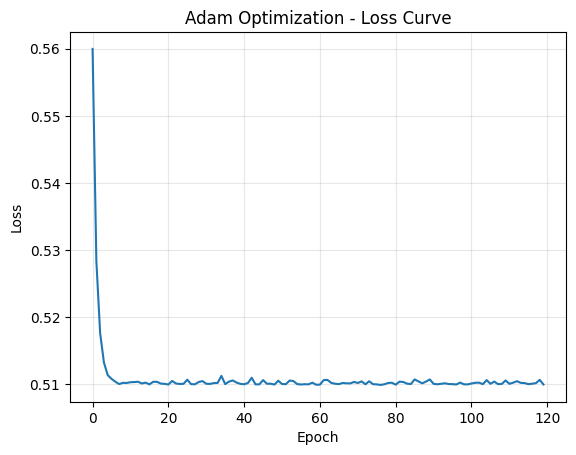

In [3]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

# 1. إنشاء البيانات وتجهيزها بشكل أسرع
X, y = make_classification(
    n_samples=4000, n_features=12, n_informative=8, n_redundant=2, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 2. تحسين الدوال الرياضية لتجنب بطء الحسابات
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -250, 250)))

def bce_loss(y_true, y_prob):
    y_prob = np.clip(y_prob, 1e-15, 1.0 - 1e-15)
    return -np.mean(y_true * np.log(y_prob) + (1.0 - y_true) * np.log(1.0 - y_prob))

# 3. إعداد مهايئات الـ Adam (أسرع وأكثر استقراراً في التقارب)
rng = np.random.default_rng(42)
w = np.zeros(X_train.shape[1])
b = 0.0

# متغيرات العزم الأول والثاني لـ Adam
m_w, v_w = np.zeros_like(w), np.zeros_like(w)
m_b, v_b = 0.0, 0.0

beta1 = 0.9
beta2 = 0.999
lr = 0.01
eps = 1e-8
batch_size = 64
epochs = 120
losses = []

t0 = time.perf_counter()
t_step = 0

for epoch in range(epochs):
    idx = rng.permutation(len(y_train))
    X_shuffled = X_train[idx]
    y_shuffled = y_train[idx]

    for start in range(0, len(y_shuffled), batch_size):
        t_step += 1
        end = start + batch_size
        Xb = X_shuffled[start:end]
        yb = y_shuffled[start:end]

        # حساب التنبؤات والفروقات دفعة واحدة
        preds = sigmoid(Xb @ w + b)
        err = preds - yb

        dw = (Xb.T @ err) / len(yb)
        db = np.mean(err)

        # تحديثات Adam
        m_w = beta1 * m_w + (1.0 - beta1) * dw
        m_b = beta1 * m_b + (1.0 - beta1) * db
        v_w = beta2 * v_w + (1.0 - beta2) * (dw ** 2)
        v_b = beta2 * v_b + (1.0 - beta2) * (db ** 2)

        # تصحيح الانحياز
        m_w_hat = m_w / (1.0 - beta1 ** t_step)
        m_b_hat = m_b / (1.0 - beta1 ** t_step)
        v_w_hat = v_w / (1.0 - beta2 ** t_step)
        v_b_hat = v_b / (1.0 - beta2 ** t_step)

        w -= (lr / (np.sqrt(v_w_hat) + eps)) * m_w_hat
        b -= (lr / (np.sqrt(v_b_hat) + eps)) * m_b_hat

    losses.append(bce_loss(y_train, sigmoid(X_train @ w + b)))

train_time = time.perf_counter() - t0

test_preds = (sigmoid(X_test @ w + b) >= 0.5).astype(int)
print(f"Train Time: {train_time:.4f}s | Final Loss: {losses[-1]:.4f}")
print(f"Test Accuracy: {accuracy_score(y_test, test_preds):.4f} | Test F1: {f1_score(y_test, test_preds):.4f}")

plt.plot(losses)
plt.title("Adam Optimization - Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.show()